# Drug Discovery mit Machine Learning

**EIDP Woche 13: Scientific Python**

Wir sagen voraus, ob ein Molekül das Enzym **BACE-1** blockiert. Dieses Enzym
spielt in der Alzheimer-Forschung eine wichtige Rolle. Der Datensatz stammt aus
[MoleculeNet](https://moleculenet.org) und enthält 1513 Moleküle, bei denen aus
Laborexperimenten bekannt ist, ob sie wirken oder nicht.

Die fünf Merkmale pro Molekül stammen aus der medizinischen Chemie (bekannt aus
**Lipinskis Rule of Five**). Dasselbe Grundmuster gilt aber in jedem Fach: Eine
Tabelle mit Messwerten (`X`) und einer Zielgrösse (`y`) findet man genauso in
der Physik oder in der Wirtschaft.

**Was wir heute üben:** eigene Klassen (`Datensatz`, `Neuron`), NumPy-Arrays,
Slicing, Boolean Masking, `axis=0`, Broadcasting, Matplotlib und eine fremde
Bibliothek (`scikit-learn`).

---

## Teil 0: Vorbereitung

Zuerst laden wir die Bibliotheken. `numpy` rechnet mit Arrays, `matplotlib`
zeichnet Diagramme, `sklearn` liefert Hilfsmittel und das neuronale Netz.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier

print("Alles bereit. NumPy-Version:", np.__version__)

Alles bereit. NumPy-Version: 2.5.5


Die Daten stecken direkt in diesem Notebook, damit ihr nichts herunterladen
müsst. Diese Zelle einfach ausführen: Sie schreibt die Datei `bace.csv` neben
das Notebook.

In [2]:
import base64, gzip, pathlib

DATEN = "H4sIAN7mAmsC/4Vdu64tOW7NDcyfnN6QRFKPcMYOnBgwnDh25GQAB/P/gMlFSmLdW7sn6Aa6ep8qPShycfGh//jvn7/+/f/+9z9//v1vf9V//u3nv/72869//59//OMv/8JUPzJ/5FNYfvin/chP/cu/dBmf2X7ap9P6see122NZ9TNEH7P9yQ/91Lof9/VDn0rtp9vjgpe09Rmkj7lPfcV+LFM+verjtRoeD/yY5TOWvXpMfYd+cdpjHuMjXR9P1j/5sT+wV0iPN8vCKzBo6c0GzR/Rp2Tfaz46/gx7XFr1YZCPDnOhT6stP64xaCHymTdfkPKZQx9TXTo8/V58UmeuM/6U0bEgy2fYPqPaF+ODvqZl2gf5U2PQFXPpY9oG8KeX7qP2x2XYqHVN+8rDs42x5RjsG4CnPPXP2ebSBn48fUnpM22GpTSfyvD10Mc2OvvxOJs4dYbF5ED/0za3+Wb1YlPRee89jGHwZ+p2fMaY/mrx3dKP6X985vLlwAe5mMDoO+bAE9/Drks37c112Xbznoqsj36KVERqmopOUH9WP23ZExUIFzxbUgyDlwte7GG1QesqJdllXQ1do/5hnpCk6ZKkMi6QURPd5htIU382bR7TVm5Lnb4Wq1wgi+xvYJUjghy1jjeQrxv7SSG2QcieHS19YpPW/bs/XirOdgZraUkEmHRYtkICgak/fgaHCqgeVN3V6tOjLS8QDJXS+1R0n3wl9GSOewSH7ZyKAGOf9kzsdEM+GaNwqa3TBWB1yRJ3JyKYiK/Q1DfYaaUifoibL718aMZR61sASAUfT4sMTC9GHHLfZ3eBa74j+F77SFo36ssFXDDjn3qOme6iHqos3kJia9z1AA9f43hcbP9VutqC+nOVwZCKpipqYf992XhOW3rSAfo7us8DAtA+jemOjUvR1TUNuhhzdn1Bwxe+1hB6f1zEVZRwWvqpOz1tJk1nUqGZl5/rasP4Q49gWTa0Ef9DdD0gzIP85e0IM3QUNjtW/10SWY8DdxzgeQWfGYKvc6k+PBcX3SnCTtWFzx0V0Ml03yK8Fb8lXX02OSx4b2xVLSq0zV5MKjWQjebrwcM/2MRlPPSIftBOOw57jI3EdJP9dEk6Ucw4Db2Etl5vQhS2pLi8xKGOg6M7gqXU92PKwwfcVG3a46U7Xm1sLRQwmRJXgZl+gv17qnLIZKBCW4eEq0b4MMGk3YemUF1qJU5O3SKgAyr2Gn0yYn1oqlUkUxgmjsdo1zDDYmbmiPiZdV3tTptV/TJDuHynfeFV+0Jt9UrYUUyb1JDriHVwS37onj6sWbWx3UOt9oINOIyeNlqWSrIdsn2m4+CQrYGZAbfXvvLUP10/qyJeXeG4DlFt0U2CCFY8xstiW6GnukwcGj+RvU/Vg7YQqpJNt6gtK6EZhomKGRjf6mKbSmxjZkhLtXc0/A/pcSrNuDvKKPbJ6gLeC2b3479l/FaH19eGQPZJneKCgMsPVqnaU+rDZFj1YWmh+fDi+Vk2vFHciDOeqrXuA9IShxqv4LKVp/7PjuXQp2vZftqKFpx+/buO0VWxmRfbr45dtYfUXLNzow1T9PFQezZ//lAR0L+AzOnu2Bd1UXGEFzBG80GTrgZsO95RfRiiM4H6LFN8Maqvv5hp18Uuc8unvbgWwxJ6YHlhDxuempKzqbThn8Nq0MCxKao/HbT5IJpOwhZO+C5n5+UQZY6OE+WzUM1uiuJTp/92+mt/U+H22zbtt+WzioMt339dNmxpobRLJhS2CqPH8beHekqBMHmJ2+R5XmtQsskI1VJcHzu4EGyzb1EdjgCKrrlN2HfTEECHoMR7fW0UueoKqrhKgyHz4ZZATtx9Hbuvudoa6OOydWkMGCPr/Q6MFJxM2wia9W7EC+rBC6qrtr09fa8YAceYxO51PPibmmxDb5NrzcWMenqFARagwkrkEiVn4xmoB5oiREd1ULez2EYSKGCeBSmhDVnx4+Z6pVe8N1ZtNXuFrQTdIVOHPtdvTglLCuHhsJkyQjMVt7o4oOpgYYF8Q0v1MzdobtAbW2caXsF3+6n36JthtK2jARXd9srr1/X3MyB2efU47LVqRtlmQcUBZGzdcCUhK53jUmEwi46rnU/pxgl8IalXKHVjPsu+Re6Rdf+UuInoLR1XA0FL4JFtO4XZss3WlK4fYV/GBpeTsJe8d82MpQ5JNcRD66jTiomZxqZ94psBErMnZpzvJFQaCGpVJBAe9Bab5OjU+gjzh1WIkdUmVxiIVXGaGjDn8ryAw8aYXr4/den9o6hqr/ipz43mxzyWcHlV7WG8q/rcGK/YLy7dxqubxv2OrKlVhBH3YxGr0wxYU6CGsw6BDkzRDazu2meFzAYs6WHE8d5h+9g+ywfgD/XI47UK5mDa294g2PtpJ+P8dnTHkQSJ3hNWxaUf03Uovd9Fa7rqzeS8H4uPV8Ah1Re3jl/2s5QEDDjwOQhfVSTRAPdGnoW5tKYma1r0qn5/s+NDKirlLlmNIRBflaE408y3btBMotMaDJb+NsTXP1bjvbO2cDuwkGFNzYdreyuq4tAKg1wHnpbvT1vvhmRtzbjd01LFXGSDgEWulFQS+Bd/iEpwA1mi0u20i1rfCY2vpxwKEBB8EWzLH2r6dEv017pg12GCkamJ0+nK0swK7Fq3DQdLUM1EGApueLnTBHOpXC17uXoFZo9U0S4HaNO8swZXZW6UOIodUlOD5qJJEBPAgy4dI2aK6cCOm9cdxFAgPzEY78543zD6/XPKRnwMaankwF/aqD2Ulhn4FtIfmBLHpw+QBPFUVbS+WcfNNewoHGnIjXoQMTiftOr+Yp9bDSsaoLQbg6Qq1j0SPBwEBWnfmvqtEZ6/0UpAnqPwgxCII+EI8SB5NjVis6sBU4DZ2e1oP0YQM7ZTprMw+HNnrOsgpk7N/TxraViLbcZjtjhV9Q1rwd3q5nmoHiqZfTD/BxrDOKzzNSnktmqy61OIJ6TfVrKW8VPP5qsyHGAWq1sgXwgy59reMP2suZ9TAT4MEfTrFJ2nAv8uJEJRy8cfutF3L0UXxzwAFTdONKao3it2ngRQZz9urbhGbs31MSanZ8s8WhUIs+fnqdjP9Km6FHdyVa0CTnYdacpczIH7sR2hsK/w7cR8ftVdwKKHT1rT+Uf1mi5b9oUOJMBGc2eCpXXiVS3AtBNdyHFykLcVcIlhnA6VN3Q/JujYxv7j/iePZQ3D8OoCjScVM02tGikVlJKvczG6GVRjmgvGAc5FJLF5isschEiTPOpSnVvuMu+oRUnkDsDMPnOnUUr47DL97Mb39Lcgvu95FnV94PLVlllewiozJPaMV0pwMAXU0dmR6khqgQnY3qtuKrj33mfaarU68IeKrKs+eDFoLtWQG8t95+m7IosJAVg10bN9NXeJjFu7qnSY3u3Y6kyYGk8/BtyXq1a+7J2NGbtko0sCoI4uHMG2cWlYqO5MeAf42urNlCEgFeVXOBVkGkDujurX3QwZpTwPwQPPyBkQguMf3/vdFcS5Lqa0jKHraSrvh0cq+0FTIHZFYFZ2wzKIMmn+RcA5DqDToPGO9yPc1SkGDbp9z9jYWcwq6+Rb/zWWUaGVpx+09liOSTOdvysd13/8OkV1i5w0OU6sb4uIAyYDGfdIuB3Qw7pGeqpqADTthM3Ygza2cghQ0MyiZEzYhIOT4zLGTMKp68vJAx+drvRwv7DnEMf7xEWBPPbFdNplw7taEwg6zRSuOWGSyg/ldaMnealZ9b4f+znTLr4fuE7xDmn1nvChmsNICf1xfDACY1CiDNYqBaSW+GPa0uuLqioFyxRa24WXyH1c463PGTKTIrCtzVmasYMO4Cy5G090NFW1gIg5XNvRRugqoFmbj/jSq9Y39gdqTcmWtPiglaADC1299m4Lvjz9stnvusceDzC1o+XHgkAeg0+THQcy+OG0LvlU5oOd5tZu9ORLWM0ew7quh+wbNQSMPgbWfu6zBpZjM58+tErbC1l5xGrUEPviUIyxzIoRp6uC0MSXz54QAb5BV1EtA8NojsgZhhHG3AH9gQbd/oxiqs4gew8+ozpBBXtber2v5W7UK0T2BhyM+ijQDdzS5q1NXDDl9dk7rUYWuG9umUfI0MYwrlLsWEwjVcS1/g3XgT6JSKIrIyFnuGXmp8rhuP2SmfbjXWTVuMT3YvP2Tr+jnU6uyekpFgse65zXtnZTADa9iRDsVi1daWjEh5sPLYJAGxe1h+brs8YgSnzOX21hXDtlCiNcWPzXK8yJrre/e27EC3NSeCSJY/PI4epHOIP/xBRzDY6byQMBPg42jjXQ+HUUWOE4ntZ1f2s0BvXANkczcKnOwZW2gnG23+pygpOVluCVERYSwU/ZIsstgpE1wmHz8ZTwhnjaW3OIMHusfdtzAxZTk3l9wdEAo4xSyjDKwpxwxCqlVWPVLGxmdVW5gQussOOXdoOGIBgRfuuUYipD3NZ2yrZ2BPxsoRXWiXKbIDf+FWPgjI1kQYbSAROT217QSLi2wOdK9jfwpwX8+zl6fQAHqO2EuN1tthCQiluzwRy8az4pvFp52PCjsWoyWt+glR2yhaBMzkAZBo8h9mMmk6rkq7s8snHA3Nvqpk8kiawybzi/LVRD+La6/OZDg9KT49tuT+OQFdXBi9oR2PuZsLsukvHI+q+WziQUVAVB1ZMlmohq61GjDPwsewfCNTqnIXsgULebslI1CgMHqoxk2m3pOiEUkP0/thMFoge0RNAdSjoBG6/5kLltiXbKzHXzcH7XtZJKaLiVLD02io9KNfdWea3ri5GtUENyxkhr/Ao92bKKjMuZY2URp8gm6ZyDiTvpiauTlhFfFoMi5sX6nGW7edj/MrObcCw4FbezY+cCQJZprDtii+3gWI+ZVEBv3WGnOk9J7lmDrWpMlUGSGbxn9TCOGD5ZMeK+zRZ4lwLq57ACrfj3Kh7vqKhliABf1vFwEsRhOAVgmIf8AUO3LiPUZfvitPLm8UmwSmi2InmBwKimLJzaYPegyWJ5uvtFbhT6LxktoCVTKomeA4iw2YCDC961kCiOQQjRs4P2zJQiRMSyzps0ciDdijls6qdDQ9YimRBa4Sj1PlKc/WSOUZV8DArvwF5FSH0d4pAj0nDE53giEihtm5ASuoblGgCmgD1SU66GmCPiEWfJmOU9JU0ooPN6IHg16d1Oo9u3C0RfAZW5/gg5Z5htcBG2V5hSIkkRJzA73ZQBE+0IIUuCi1I8WNyHs4SuBof4gFfp2bCoK4MIfqGUKWVQwSPWwyHIOL/lyGg7lt5SiRAl6glrkCI6HAKCt32eSgRlZ37oAIRqv3qYK0UyROn3HF6sUvPKeAIKyKQ0VgIuajUjoBajkjbSU1PuOC4zP1WrjUQRSyFKDFNz3/FkRPYDa3CMyrjow/LmLGKkZGdN7sDGL2PUNGHiIJLlz57G3Ka7lI3SrvfuaRQrEP76Ey0uSrMPN8Epn9KyNjz5oNWcjDqQ/GFGgrK1/QJ1dd1cSGbeZP3guuziPocd0FH/xVl+GwdQkXU9CrOqHXmMkdW5Nh+Akzw3Km7bdewwwaPllDXNNfJAaa0Pl5Iiu6VkO2V+gmOBnUfatnK1uJrmBnB6LAYzPA7m75BNSYNs5fDR68M615ptnR18wl71a0RZVTH8udL56m0xjWnHli2V4PKq3Y2zgeB64i9juV6rky8cJItSIZ+u1EvkW9aNp/8kF0h4OkS0YMTNDv4mW5bCspCwlpJTNbxhsqWKsVOiTCwtABq+ZFy1d48QzdvmAMZuIso3Q4WVnfd4kOO1HgAJyAwcI2+fJa2ZzuycQan5D2I4f4TGC900g99qLYMSozjhrkoGsOTBQCnpAI4yPLNap5pxdOkOr2ev2X00UgBeTHf0/8y/pcIX15gyRRTFghLjBJmGp++NliTri9mVEStU4TPdSMDcmRY5b9VYCGiHOnoam8X97YwUvvJ9VDJHzmLwkJHwZKzlsWFIGAVSEEkRhkY7KSwTzMsoN3OYZUSk+DuLxQODUFVd+OZOm2sMj1BTdnNCbYQHK709HTPLREfugRksSqmJK7L3VhvJV91+v8bokhmbYx90/G571+GerzBD42FIeVyf3ThFuCOrt2QWRDyaWcIQzo118NqZjbZBZQxs1fTe3x02PzKadmVwRk3GSGrzkF0F0b09tkKevcu1X6NnqVCI+GX+A9lNyDUdac1octjzoDT8YxLJTR763Iq0z6gtkJ7Ez9eXP2F25USi4Ek8cBxy9sRTcq7G07E7TTHYg0594zVdcFVAauTcaSg+ip0flQ+dmTzEhtqgyL+J0Bl8Rg4+YXvh3VVs6/Jr4QN4rbFSuCdCHEbrtxTi+FJMoobYU/R60laG5afp4826047jgu3w8PBhGjnI1bmyQngn85iXU+a1zUhD2/Uv0LpylaMmxQb131siYi2NwMPnK6Urm1IxdgHc8TO6i/xMiURqOvQsXtGz8rexQSeMngGHx5EYMb/EVZXuwsVck9BaMhwIrJZU0I4dyEzBU2RtIpWaMkU8PITU58oakzyZaMYmRX7CQLDeI1l7AB2+todUj67qVF0kLCtrXCBk4oZUwdoioSmj2LqlbXwfmmmg5q5rsig1zHmruUAJpTd2mOQBu5zlMHq1prGRihVgrGGjlDEfKGiWnpXuiJyMAML0J3UQ1QqkTFCEYRjX0Us2t5V17vZoavFzHlvkP81eylGYM//5BLWgCkFARB2FMMxPsbSHlN9tybqevJ6dNY3HhN2Yz3mxl27lBHHVt/DV66hZzQTXO1v2dDgyWnmmuhF1d/0gC6Xw+CyOwVbxMoB+ildaRGp6AtbNaZMZkf+dTDFcqzlTeyB7JGDLSIkQ74wq4L0TfXwBrdXBebr3wxVQ3YUkO9MPtMsnupepGEWaGQAeQYZyoJn5EGqaGdiZAm3B/l31N4fPmVtNQd8vIP6NZUFlFoztwu/+LIhur3X2f7bkKb16P2Du2KNFt2DEtadOGBtfv2pfM5NQe0Qrzfb9ZCPMs2ARU+ROq1qciGVJxSa1+7muMyEA1hQFATwe/tR/y+y5aKv70/kdTFmBBEjmFfwTbYjucCFU+qECeSD3xc/VetAao/INa4yd42YKdV0qsBqLg6SfcTHABjJlJtbYNJlb2DGuwUJdpj01zm9cs8kI3hccbj4q+T2e9KXUz2JVWHcrCrqRLTuGoGG1QCEVd1aOpzzv03Q485H1jGzdpZUjmJZK3CLl9xrk12NoqdeO8lFVVH9uKB5Bmyk5/mhubIXnHY9dT9EKY0ZZ2l+JMUucGHRQ7z5xV9okz4MDC9csV69W5P23VluBAxfu/NjJEShYHDWHW6IQzkzD5VhgW8CJM9/kQouhQVypJPMG1QXu8paOieWrqPC02W90l5j9pdlL/fKlMh2VUkmo1BgQUIZlJ9e349wtoIeaw2fdcZ/lFfVE4r6GTlTBmuwYNTbv4EY119c4pcgri9BssXR1k+t+9Ymxfl60UUeuU5tBKDRKWlmjWJ6aUSTxDNSDPV1F0lrUqFXtkgQK+hNlQyvlaSIOhRLkspJb4wWCpsNzeSYjrdS4jhQCMFhiVcJqIZIOVj2FYpBaMsHH5InsnB7COUOIbeQIQus3uJhoXdN0+PWUPLDlerWRpIHZWTGmkzpf1ggYBjlNS65IfovUv4Y4UQVGYGCCCiq7Zhd8DZEkBgYRmRF1YMkZCNy2as9BB6QV1hvLbL9kvI2r06J63PyuZ1F5AINCkfEWMyxOirRERwSM5lNmvFIJ+5aqrUIpoJcWayToJRQjfkQAyqmL7heRqWthJ9kD6Lc6lL2cn7ndLBITS+xozSJsuJQ9+eYh2DOqEMZIed9W+wSEVTM9QMGdjBW1XpH07WYu0+e0yM9WyVhVIb+T3GtmBEuR7DrzwdhhVEvxzfokiv63MYv9oR2OWSkDDEEhU2t988DldDtARLjO5BEb1QIXSnpOszE3V6KdQGLJtiu5HqQxrAYKncfI8C+yeuiKiQF/5PT0qILpD/twSvpuPGakPAY+qYQVxro9PNTmFnGsBwNTnOISySnpEQ8Z9ZcwD1K3pKZt3pTTCKqlf3dU3hUKi/t7vCiH8odV+lnFYsb9zdSDSU9PuU3kQIYQF79nSKmsSPLK+aW9e2iVuyQtA+MpkfpxaAjLmRPQBSCF+YDu5ul4g9a1ihYMRuS4B8I/gWp4gj67mqyGHWTq2XVeNg2rkkhEBrwwVDE2ymOYxYFTWZwP7fAV3u4A7QJyWDlz+o5HAc0D0DP7Bb1WykY+iHzsKUKHZSR2FHq8h5a6ebZjuaNQRQKJlDctVQKje82txzC8kKxEDXs8pF0+CNPX6y3DteQurM2guc0Ziv8sqI8OFO76RsVj2UkVdePE4l6RYBJtpqcu657e5dANVcbVuWMt3Nr8H6rOgq5c2weLCkQP4gYBHkW4+8jvWJOXqhomFGSG74yYEtwmHwdkr8RkT1OceDEqXMqpjLfTmUtjN/e7+RGfx0uviRIpqSNiBH2XMSpi8mXrEr0Yog5XJg6ta1A5FcYMbbu1XIkMOvRFKJ5j6AM20wkLXmhsw45JRzSgz3Un/ZZ5UN6gbJQcenoR1bsflv7tVbDbyEXdZJBKnApNuXnpTZgzOhuH5P0ZR77sbZYFN0PCwBTvpoO5jUh1jkLwsN9t1vuUVvNFiwBvO9XoKOHmvJtejsmR+bZHVqEKDKS3NAnzdD3mR3cWQT7TcVP9DVbzj3xDukfgkIGjzjuEYa1ADIoXY8ooatZvRCSceNrDRZHYapsgieLecMz4/vYtVx7r0CM+UNZtDWAZT15RH7B9fd/3cw6bzG3rS9gM5PrJurJ+EDpzOgBSPJXKEoDpnpYeOb2LZl613zBayc59r9uhheIYDv0tE70fSS3VM6d7T1uksBvFzzRS5TyYZESuVxITowEMFSuwPb5VrKWVMOorRm4LYPqkhhNPdx5wqyz54IRrS4ovby9+7jJheG1U561/huUC1NvcUFQE95PxdKTVTBSSW3vr93jaRFzfUl424wTFA3v9yhUynJHIEipp7up3KI6T9MgPNdx5PBsJ+BkvLQnsqh93unoSip2Wtuui5ulOQWimcKqlirMD7K1PHkX8B3fXNOeXvPLoReCmDgTBfsxWCEKJrZlbkSOVxOsBj5EJP/FQX3EO0OslbJerrx4fq2Umnc8Rq+tTbocD8Ype96LuMajd8dSs0QLET505FRyVf6fm+i01YCtRUBK0knC3KNhJQa7iOWhySbWtnjeXOkrSQJYOYRBLFRln8zc5kpAXJaWtGMPx+JppLS0VATCfOubna9E3Sh/16iWLy6AmrfaZLIdRHcBq6uf89F1vjMoeWKQ2g+/LT6neh4o+0doGzQymk4Dlre1NSWlwbXsrWDXNwv8YjWidqHAa/XCcuFeEhsn7lUT12qKTm1A8i8TT7sOZr8fcwoNVrRzJo1u/wjMpM9kJM2BQCPNaKlRJgXOvlE7ogPsokZ1ybPPJeukPaYucB7pKCU4lKAlOzQ/6jPYWLY3qFRiCJ1sngXFrA4JvX7AVfTdwgEeArgGUytoDoxvhLcnycABOb8MSpsDAEDK6WHpqLOENbFDbd87st0Nk58KUTI34ydo7LJjwoAeYie4fQRe6kbKyZ+QS9plA1k7ALZSgVzTjIvRMO3OzoU3vHpJhuiFWAAGSmTqQSDB169bDf1eLVn2NsIoVwl2sxpHeWU8nrhLBFgDZ0a/teumZVjxsColaxqefzTc0IqeS69i5yGn1hJttE0/voWiA4++l4XRPkySTbxYxqDpnU6/8WwU5vMHK4crht+EjcuRw1is90TfsIktCPX9FhsedGdod1gDd0S8CPduwNGXe/hbmD5iOVcwd+Vb3vQth29zE6XUdgUQqmo3IVQ4vjH0MAmio7YaQvm2/RwCjkYpnE0jC3e+I833boLf4tBs5BpU/0XzpNvEZKIFmDKxlERFv55A8uTABpmCiPD86MmEvONz1bVG5fUYovntiV/Ta6XUXapXDZhjHVjc5EF4fe/h6JJmWaMnUI9cyPLnfOnsFuBUvyGkJFI6I5y45+ZN2Ni0TAPLbn25xDbqnZ129OFrO1Wwv7LiQV0dkx8RSFIGnel4LzSVdfKrgdwOmV5N8GuLNlfTq+6SFIwbCpSZTX4Yv5pip65XhJqTd1zWeHg/6bSxJiG7VyNYJM+120wK6llFTVsIgJ/V7BOO0DpIWdL/oO8UxvF/PAWs1Gc4XHr144N7ROM+s3GPKwsnbRse5EcUjT7cYgEXoeivGWi2P2EjG8z0aB83NNWYdMZtEJ8PymlQeJlW12R9muTxkcxSguh7aKQKCFofOK3wILsTtKvZbFd099YTcsqfXtk7twFZeDPLEqs5b7si1bAReHHlwNGAQ6JdBqecd9DUSuEb2MxSVgp23/JT7VCMP4ulGdBvxvJ9acXNoTBDdob3Ff0N38K4crNkUIZeNJ10odAyMaZ97BmbdFTvjdsxBujJ4g9mT6qgRTFp9JnxDzYkopQqSoCk6WfA+Vk+8V8XO8Sk9DJRIHqRdUTXEp3UWh+t59HXf1U/UZ+pJtz32KRQNUR4zlplMat115i1pHmOw0T/MeJ3rsL/DjSVhi1amG3sLVMnJ/FpVO/wiT2w4aKo7Drd02Wu3qLgCFU7vje5xBm6SM3nE74Ghe5RrdqHUWEzh7jpVzgeZTD9YrsL3uNQbcfEtyTFDyxunV+WpaX/JzvuqYKRGc4s1eTeh2aYeuoTSLCxmBNwmkZrbdhc+CEl/aqNXy+cdVC39KzN6RpFhj5skosW44xpU1l1J6zDoJWsrcvDDI3bv+TRnKN4hGOFjii6uc/OoxiWj3zIdLL87WEs/tfMlYmfLPbtz5keD8bWkmsDLvp0qfWCUS+c05Vfwpy6zY2v3aeQQXBQAiRM+f9fsWtPmybkzMt7kuwC/7xzqJ6DD+SQ4Fe/vfFhIPlz+W7p+SSlOlsx3MdmA/qvoPSy7F6UxaqtHMPRgxSMqheRCMrMEEoGOs2xtBLfeeKWmiIz+qRXJ4XKJoe459ZYgd6cB/g4547VfhG3ayxsIBWj2/VBHwvnNmYli4+xRSNJmCqwEnF9zJZfNXcx2/Gz2WexcyUF3FnBzncmf0c0plgFL5o2bTphCnH8uDX1sYyFf4xEyow10HRn2WNIxmn4ZpDqL3lPTBPbm0EHH4nj122C6eKYtTmjrIxrYFy+1sr7Q1oqOztBeG6GCm4rx3uU9NpnTwMwbmJENLaeH6OjhhBXJ+j5+u4hS08qFKjhDCzPZPWsjifKkuu6iWztArybuco/WsG5tCJ1NbwYwvyNjiqr/MRNMpFZ36KTdjx3ebuTwVLBHBDKYD+7Hj93bWhlLNWcchmTMrnwy/CImzjRaJN61QNxrHyG8oY3czdI68YJ+jA2qh2MBe10vofju01v5LIIyzJIZkiJRoZGDVihMQ3JykYRXoAcYJv2K0/vXDFKijbLck41ib6+Za7epqGEjD+DUHKoxrLEbpiYUNPwQt8VXnqzbLpSON83bbVRHjRXjcVdsNHbpt9Dm9FpUe8wtkqn09elxCeeFbctauHbmKQEv8y89ZSNXZ816ASH0w0COdmZY3rsR+3EhqL7LZ//e9fsyhBYnjkKzoHzR/MBiUfOybu+Ng7eoerXcXkyqTq91V33zRLgaEKWk4W4gP/sjjIC4l2Ue/BoqLMh1LON2z+TRI2BU+kUAYRgo9OReyd8T04p3GEfY1srATvPiPWFuORocuSXWH/wiv9epjbZjuZbuX2zr10FYyKRbPbN2v13vEAgCLMKIKEsY3uluA6+EIJSh3219MpttpBC2aLfEdwup9gLet8VtZ2IDJfoGJwp1dXdzBmca+PdmIWE2UX/puV/xhj6Kc4wrqtO9y3l4KQaEslp99V1eY7y0mS3hHC33YnpDpTOtw/sC2zTAyfeSSEbLyzCfF/1Y6Jl6gGTOKQkcndPZarLp1mQJnfiKXIwGnzyCZkco2064pJHwg8dtOYKKB0ZFtKqPFbXmm9qCA7Y4YeC6U09B2knoo9dcC6PiQBNxDsUaIoCr1Us2RJEmOyclBWN9Ujmlrsr2Tg1AwcDsh6/TNZ1jncNRGcIPwOUdiWrycsydWdFyaZ50CPTlNNhYU99hVE3LqQo7Dr3i6tUCPlxigmuUFUXOwDENaLW8ToJXSbnfXlQYXIMFTKaEk/6kpz0be2YIQ85v9xyJMccOsISf5yrM/Fw9oUkrpLYKjDUzj3x1VGpHjMQvdOMe+1KZ8trGZ3NaXmlGTx8QuqiPeqWheVmsUU2SKTT2DhNld3EKVysacpe9c55h0MTlV2a/rhZ6OzsNkt6MxLpdBXfpYTPJHXG4kfTDiJAH5ajxmR2XmvbIOna5QuypW766ew0nayR2r1kdvbkMo2YR9pJmcaqg7Um8Lc8X58uaQ3tD7Z5iMWoZvb4KnZBlXxHxHq1CHz9vmNB3X0mkT6C8yO/O6ufIWD0JYGkHONmQ5SVDf3uoWCFJXqeBVdThC4KwW8uYSYVCGU8Ovob6Ir5I3BoUeSzNCaH2XSbQKxghoZ6Cj5tjibTBdggSSHZNuuc9mmKd/D1jeVI6SJaJig7ewi1hwsOH54skrIAaztoi2v0Td4YCtv+UgEGjDE/CnBGXn9+R25d9jutPjJGsmekZ4hkqPL1EfX5PkDJxTWm2YSTjurIx1+2jb06Rpz/OlqD4q140BAEsZPRcO7pjF5NKvrsgQj3wCA6UR8itQUMcJ9SqMJCxt/ZlRK43CDU1BZ3lTtAYGwSe/qRNl3vr1KDoP8Q7bk2ej9jS3Qdcd63Ogz16AUfoOYIs+nq70hNFLj/naz5svWSHga9naExV3LxxtuE9H7KtaHhAUf0TXfhLNJqRrIx6pBeOmZz50cQhol3KliIp4mNotWZKYbt1s0ryb99Th0qYZCeZTnbhKzBGbTmc/5ao2lp9dby94raR73hdpdS7s1G66AM90s9tBFutvyv79w2akRu907tuZt6I7tk3xLiih4msRPi1XRy3GwHSI8dSeCQUYx2NUO08Uj5mb9HMvs2Z9Agym/1+Jrrb+eWWj1V9h+qsSXNy8wyNlkTKwj64IGBZUPLcb1E9e7PXmnNQV2BtNyuyiUjxxL6kC4ko4kZBydJ3+IAL8FZc43WXAQQRSP4pya98DxO86jyEqSYSl1rKaLHeChZ1QlLBYZ7Q6gS5ETM8elfqnYK14Whz2Z05CsK4Sk0OxntiJ3KMelyNN87VOqOU6KC5q2H6YeoRaOJEv552R1Z3cM4cLno0c4G/90dW1QiLtexChY12zSNau8523nQty+4ZqBDwKvrIA6txCvouow+XU3DDUOMbeAyI5uXuF/y15RsyJqUEFLBH1kTerxa5VnZ3HZuP1Ise3Uv6Wkm0XvPdTbbjRk6+CAB9agbKzWbKHz8nrDJnibNyqF03dykz2b0FhTKKCKbUuiKni2W6k0WDaw7bcXTWmvMXasqb9qTkWUQtZnSOvkNrO3/I+cAz6bhwgEe+hWZIxIXmyrApgtT7Thb6fukOSs6Ql1lmzhPqFHc2Nco/rtFqoNXd0Dbuz4KLV2tN6sIiON4ItPWs3N5AnfWqwJ5WGilTAuViUE63grWchrQNncZSHYOEIV+LokNliXJnlFlKNh8iu11OcnrOTT2j9Wtdj2gJcy5NsOuCRjQEOReuAY+4WbkPrS/JcGfhXK8YFG11oJNuyXm7NAzsM/pwtHzHWeRBbQci28AW9xXt+a4C/MezX+QSV5g4RZyqBDw4VcGd0M209DSbGT1SNzJ9vVJt/7hFfkBtvxDVck+SZahCORpSSsnevHeoU2L33y38Vh98Gvncp94T4oAMGSUaLS9OMoVN5qgY62eTlVJ3oysrb0eNtj9U0s7JiFtflS3Ib+7ipbu0033aOTW44Lh2V9Oy4QNaWvWWomQIcbloj5QyBFxizNXpBc9XWswbW09agmBkSwJidq2ExzKjJilOGIWhXoV2dX1UJeEkTD69XMppUk6nO96OFDTHG14R8fyiJQWu5JxaByG/WCDuJYuIMcW9OZIY0fdkyi9Pf+/rsZXhisscj4hbkwu/DnK5TXdcMJtbekudu26zi3iFArlzplocA9eSDBk6foIEi46fIRmGcCjS0e7iH+ka0SOl7duzUFb50PXorocw8HpyCxw9qluKzpnq9ZZQqyZ+w0hRMMmUJA4R/B6lwTeoGheJWb5fpmm4uWwZpT5OEsCe9emY9CeXpJ3Cg17z3YGjRZqG5ISKV2fW6xka0oEkWbK3Oy3t5lBvKkWZYd6NiEU4r9qrOfVKMScrbzpQ3dehoWnIBsNjRPLlyITDlwHTCCg0Mk/OQcCPXHllJwxtQ+IKrvELKJgpt2BbK0uqyOVNa5f7HiqZ7D5bedTol3SDKq31JFFxF2AjyZG0uMWuSfrtCSj2SPS4BS7AzItyzLgYw2zpOIkLRqNuip7HfdOa58q7wSkcjvg0+ok14nvVmwUq/TKvTukVhq69CWOK9JyEdI77ZTnd+djiYqKjBD3G17yT09nkXsKpqJnPWS3uyl7toUfdMy/7dudTi+BZ5rtUo22Kw++ab5JUNGrToO92o56670NV9WWrMV1RhJ5oYcjm+mfC9k8uN3xAJoMb8EHGTInbX6KVNW47a5JKwN6PQdNzizsiK898sWBxGpROe8nQgTjjMlISHlo4+qUvWeLfyA+7HRGyvUWFNsdbvQypRWvPxOF4P5P909drEBuzaw7Jl4N6PpklCOYAQ4tQWqUs2RSt00bOsrDzid9KmUmE7ZpV72XzCOexB/lKz+/V7YFNLJSuWbWTAbeRJd04ujgif7M/bxx9ea3SDgsXE0tLS84UhWan537spDmNnTmRhD4E2/SWBsY9ilAkJQ8bpHZ0Qcmxq3bnCpLq/BbRSFzrPrMyKSe/syuTKj2NS+KqIL8U9lwFWYyFbrjr5u7kKzi06zNBqIy0O/8P7FTcQgCDAAA="

pathlib.Path("bace.csv").write_bytes(gzip.decompress(base64.b64decode(DATEN)))
print("bace.csv geschrieben")

bace.csv geschrieben


---

## Teil 1: Die Klasse `Datensatz`

Unsere erste Klasse verwaltet die Moleküldaten. Sie liest die CSV-Datei mit
`np.genfromtxt` ein und speichert zwei Arrays:

- `X`: die fünf Eigenschaften, eine Zeile pro Molekül, eine Spalte pro Eigenschaft
- `y`: die Antwort (`1` = wirkt, `0` = wirkt nicht)

| Spalte | Bedeutung |
|---|---|
| `MW` | Molekülmasse (g/mol) |
| `AlogP` | Fettlöslichkeit |
| `HBA` | Wasserstoffbrücken-Akzeptoren |
| `HBD` | Wasserstoffbrücken-Donoren |
| `RB` | drehbare Bindungen |
| `Class` | **Zielgrösse**: 1 = wirkt, 0 = wirkt nicht |

In [3]:
class Datensatz:
    """Hält die Molekül-Eigenschaften (X) und die Antwort (y)."""

    def __init__(self, dateiname):
        tabelle = np.genfromtxt(dateiname, delimiter=",", names=True)
        self.namen = ["MW", "AlogP", "HBA", "HBD", "RB"]
        self.X = np.column_stack([tabelle[name] for name in self.namen])
        self.y = tabelle["Class"]

    def anzahl(self):
        return len(self.y)

    def anzahl_aktiv(self):
        return int(self.y.sum())

    def nur_aktive(self):
        return self.X[self.y == 1]

    def nur_inaktive(self):
        return self.X[self.y == 0]

    def plot(self, name="MW"):
        i = self.namen.index(name)
        plt.figure(figsize=(6.5, 4))
        plt.hist(self.nur_aktive()[:, i], bins=30, alpha=0.6, label="aktiv")
        plt.hist(self.nur_inaktive()[:, i], bins=30, alpha=0.6, label="inaktiv")
        plt.xlabel(name)
        plt.ylabel("Anzahl Moleküle")
        plt.legend()
        plt.show()

Jetzt erzeugen wir ein Objekt `daten` dieser Klasse und schauen uns Form,
Klassenverteilung und Boolean Masking an.

In [4]:
daten = Datensatz("bace.csv")

print("Moleküle insgesamt:", daten.anzahl())
print("Davon aktiv:       ", daten.anzahl_aktiv(), f"({daten.y.mean():.1%})")
print("Form von X:        ", daten.X.shape)
print()
print("Die ersten drei Moleküle:")
print(daten.X[:3])

Moleküle insgesamt: 1513
Davon aktiv:        691 (45.7%)
Form von X:         (1513, 5)

Die ersten drei Moleküle:
[[431.58    5.045   4.      2.      5.   ]
 [657.82    2.639   5.      4.     16.   ]
 [591.75    2.458   5.      3.     11.   ]]


### Boolean Masking von innen

`daten.y == 1` erzeugt ein Array aus `True` und `False`. Setzen wir diese Maske
in die eckigen Klammern von `daten.X`, bekommen wir nur die passenden Zeilen.
Genau das steckt hinter `daten.nur_aktive()` und `daten.nur_inaktive()`.

In [5]:
maske = (daten.y == 1)
print("Die ersten zehn Einträge der Maske:", maske[:10])
print("Form von nur_aktive():  ", daten.nur_aktive().shape)
print("Form von nur_inaktive():", daten.nur_inaktive().shape)

Die ersten zehn Einträge der Maske: [ True  True  True  True  True  True  True  True  True  True]
Form von nur_aktive():   (691, 5)
Form von nur_inaktive(): (822, 5)


### Aufgabe 1: Gruppenmittelwerte mit `axis=0`

Unterscheiden sich aktive und inaktive Moleküle in ihren fünf Eigenschaften?
Mit `axis=0` rechnet NumPy spaltenweise, liefert also einen Mittelwert pro
Eigenschaft.

Berechnet `mittel_aktiv` und `mittel_inaktiv` mit `.mean(axis=0)` auf
`daten.nur_aktive()` und `daten.nur_inaktive()`.

In [6]:
mittel_aktiv = daten.nur_aktive().mean(axis=0)
mittel_inaktiv = daten.nur_inaktive().mean(axis=0)

print(f"{'Eigenschaft':<12}{'aktiv':>10}{'inaktiv':>10}")
print("-" * 32)
for i, name in enumerate(daten.namen):
    print(f"{name:<12}{mittel_aktiv[i]:>10.2f}{mittel_inaktiv[i]:>10.2f}")

Eigenschaft      aktiv   inaktiv
--------------------------------
MW              516.43    448.77
AlogP             3.16      3.10
HBA               5.05      4.40
HBD               2.61      2.29
RB                8.57      6.93


Aktive Moleküle sind im Schnitt schwerer und haben mehr Akzeptoren, Donoren und
drehbare Bindungen. Mit `daten.plot("MW")` prüfen wir, ob eine einzelne
Eigenschaft zur Trennung ausreicht.

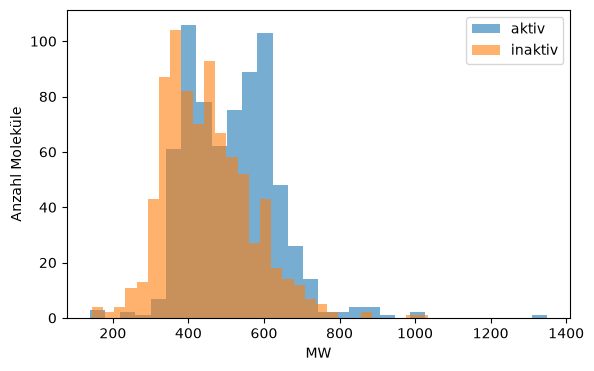

In [7]:
daten.plot("MW")

### Aufgabe 2: Streudiagramm für `MW` und `AlogP`

Das Histogramm überlappt stark. Vielleicht trennen zwei Eigenschaften zusammen
die beiden Gruppen besser?

Zeichnet ein Streudiagramm (`plt.scatter`) mit `MW` (Spalte 0) auf der x-Achse
und `AlogP` (Spalte 1) auf der y-Achse für `inaktive` und `aktive`.

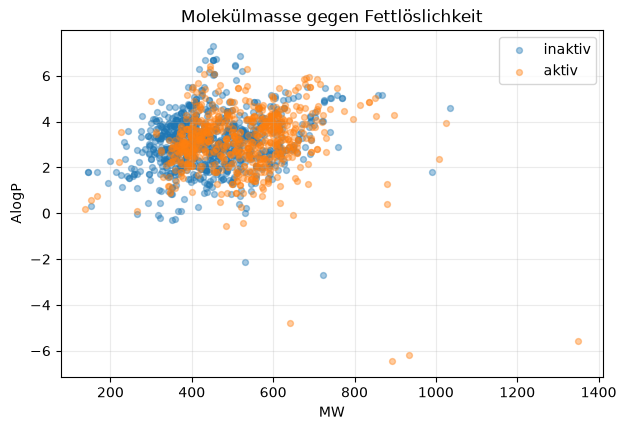

In [8]:
aktive = daten.nur_aktive()
inaktive = daten.nur_inaktive()

plt.figure(figsize=(7, 4.5))
plt.scatter(inaktive[:, 0], inaktive[:, 1], alpha=0.4, s=18, label="inaktiv")
plt.scatter(aktive[:, 0], aktive[:, 1], alpha=0.4, s=18, label="aktiv")
plt.xlabel("MW")
plt.ylabel("AlogP")
plt.title("Molekülmasse gegen Fettlöslichkeit")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

Auch mit zwei Eigenschaften lässt sich keine saubere Trennlinie ziehen. Deshalb
brauchen wir ein Modell, das alle fünf Merkmale gleichzeitig kombiniert.

---

## Teil 2: Aufteilen in Training, Validierung und Test

Wir prüfen ein Modell nie mit den Daten, aus denen es gelernt hat. Warum können
wir das Array nicht einfach mit Slicing zerschneiden? Unsere CSV-Datei ist nach
`Class` sortiert: zuerst alle aktiven, danach alle inaktiven Moleküle. Ein
naiver Schnitt produziert völlig unbrauchbare Teilmengen:

In [9]:
y_naiv_train = daten.y[:1200]
y_naiv_test = daten.y[1200:]

print(f"Naiver Schnitt Training: {y_naiv_train.mean():.1%} aktiv")
print(f"Naiver Schnitt Test:     {y_naiv_test.mean():.1%} aktiv")

Naiver Schnitt Training: 57.6% aktiv
Naiver Schnitt Test:     0.0% aktiv


`train_test_split` mischt die Daten zuerst zufällig (`shuffle=True` ist
Standard). Mit `stratify` bleibt zusätzlich der Anteil aktiver Moleküle in allen
Teilen gleich, und `random_state=42` sorgt dafür, dass alle dieselbe Aufteilung
sehen.

Wir teilen die Daten in drei Teile auf:
- **Training (60%):** Hier lernt das Modell seine Gewichte.
- **Validierung (20%):** Hier vergleichen wir verschiedene Einstellungen.
- **Test (20%):** Bleibt bis ganz am Schluss unberührt für das ehrliche Endergebnis.

In [10]:
X_rest, X_test, y_rest, y_test = train_test_split(
    daten.X, daten.y, test_size=0.20, random_state=42, stratify=daten.y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_rest, y_rest, test_size=0.25, random_state=42, stratify=y_rest
)

print(f"Training:    {len(y_train):>4} Moleküle ({y_train.mean():.1%} aktiv)")
print(f"Validierung: {len(y_val):>4} Moleküle ({y_val.mean():.1%} aktiv)")
print(f"Test:        {len(y_test):>4} Moleküle ({y_test.mean():.1%} aktiv)")

Training:     907 Moleküle (45.8% aktiv)
Validierung:  303 Moleküle (45.5% aktiv)
Test:         303 Moleküle (45.5% aktiv)


---

## Teil 3: Standardisieren mit Broadcasting und `StandardScaler`

Die Molekülmasse liegt um 500, die Anzahl Donoren um 2. Neuronale Netze
reagieren empfindlich auf so unterschiedliche Grössenordnungen. Deshalb
standardisieren wir jede Spalte auf Mittelwert 0 und Standardabweichung 1:

$$x_{\text{neu}} = \frac{x - \text{Mittelwert}}{\text{Standardabweichung}}$$

In NumPy geht das in zwei Zeilen dank **Broadcasting**: `mittel` und `streuung`
haben die Form `(5,)`, `X_train` hat die Form `(907, 5)`. NumPy wendet die fünf
Werte automatisch auf jede Zeile an.

**Wichtig:** Mittelwert und Streuung werden nur aus `X_train` berechnet.
Validierungs- und Testdaten werden mit genau denselben Werten umgerechnet,
damit keine Information aus den Prüfdaten ins Training sickert.

In [11]:
mittel = X_train.mean(axis=0)
streuung = X_train.std(axis=0)

X_train_manuell = (X_train - mittel) / streuung
X_val_manuell = (X_val - mittel) / streuung

print("Form von X_train:", X_train.shape, " | Form von mittel:", mittel.shape)
print("Mittelwerte nachher (Training):", X_train_manuell.mean(axis=0).round(3))
print("Streuungen nachher (Training): ", X_train_manuell.std(axis=0).round(3))

Form von X_train: (907, 5)  | Form von mittel: (5,)
Mittelwerte nachher (Training): [ 0. -0. -0.  0.  0.]
Streuungen nachher (Training):  [1. 1. 1. 1. 1.]


### Aufgabe 3: `StandardScaler` aus `scikit-learn`

`StandardScaler` ist eine fertige Klasse aus `scikit-learn`. Das Objekt
`skalierer` merkt sich Mittelwert und Streuung beim Aufruf von
`.fit_transform(X_train)` und wendet genau dieselben Zahlen mit `.transform(...)`
auf Validierung und Test an.

Vervollständigt die drei Zeilen unten.

In [12]:
skalierer = StandardScaler()

X_train_skaliert = skalierer.fit_transform(X_train)
X_val_skaliert = skalierer.transform(X_val)
X_test_skaliert = skalierer.transform(X_test)

print("Gelernte Mittelwerte im Objekt:", skalierer.mean_.round(2))
print("Erste Zeile vorher: ", X_train[0].round(2))
print("Erste Zeile nachher:", X_train_skaliert[0].round(2))

Gelernte Mittelwerte im Objekt: [484.45   3.12   4.76   2.46   7.78]
Erste Zeile vorher:  [401.41   2.98   5.     1.     7.  ]
Erste Zeile nachher: [-0.67 -0.12  0.15 -1.14 -0.16]


---

## Pause und Checkpoint

Falls vor der Pause eine Zelle nicht geklappt hat, führt einfach die nächste
Zelle aus. Sie stellt exakt dieselben Variablen her, damit alle sauber in den
zweiten Teil starten können.

In [13]:
# Checkpoint: Daten laden, aufteilen und standardisieren
daten = Datensatz("bace.csv")
namen = daten.namen

_X_rest, X_test, _y_rest, y_test = train_test_split(
    daten.X, daten.y, test_size=0.20, random_state=42, stratify=daten.y
)
X_train, X_val, y_train, y_val = train_test_split(
    _X_rest, _y_rest, test_size=0.25, random_state=42, stratify=_y_rest
)

skalierer = StandardScaler()
X_train_skaliert = skalierer.fit_transform(X_train)
X_val_skaliert = skalierer.transform(X_val)
X_test_skaliert = skalierer.transform(X_test)

print("Checkpoint bereit:", X_train_skaliert.shape, X_val_skaliert.shape, X_test_skaliert.shape)

Checkpoint bereit: (907, 5) (303, 5) (303, 5)


---

## Teil 4: Wie funktioniert ein neuronales Netz?

*Hinweis: Dieser Abschnitt erklärt die Grundidee hinter neuronalen Netzen. Die
mathematischen Details kommen nicht an der Prüfung.*

### 4.1 Ein einzelnes Neuron

Ein künstliches Neuron bekommt unsere fünf standardisierten Molekülwerte
$x_1, \dots, x_5$. Jede Eingabe wird mit einem **Gewicht** $w_i$ multipliziert.
Dazu kommt ein **Bias** $b$ (ein Grundwert):

$$z = w_1 x_1 + w_2 x_2 + w_3 x_3 + w_4 x_4 + w_5 x_5 + b$$

Danach läuft $z$ durch eine **Aktivierungsfunktion**. Für ein einzelnes Neuron,
das direkt eine Wahrscheinlichkeit zwischen 0 und 1 ausgeben soll, nehmen wir
**Sigmoid**. In den verborgenen Schichten eines grösseren Netzes nimmt man
meistens **ReLU**.

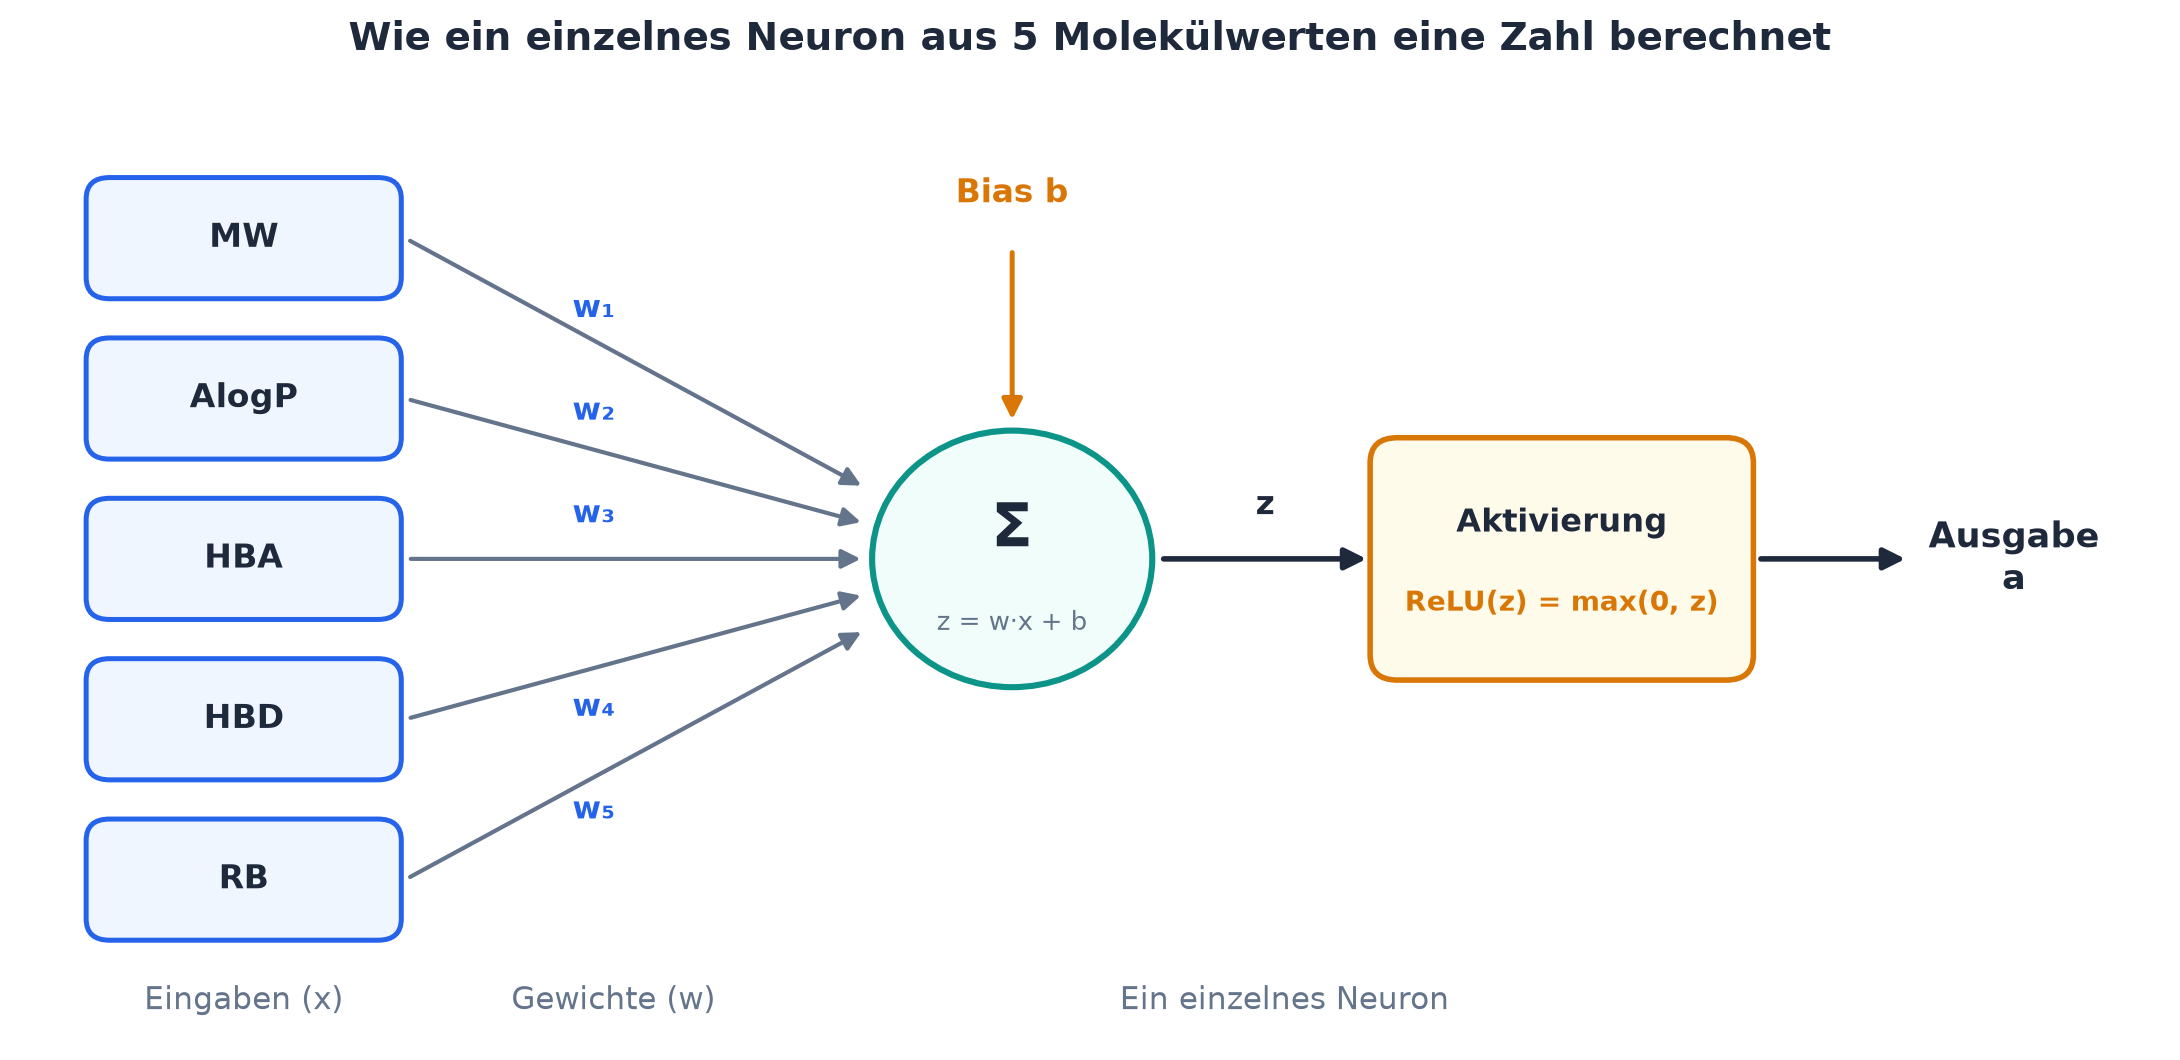

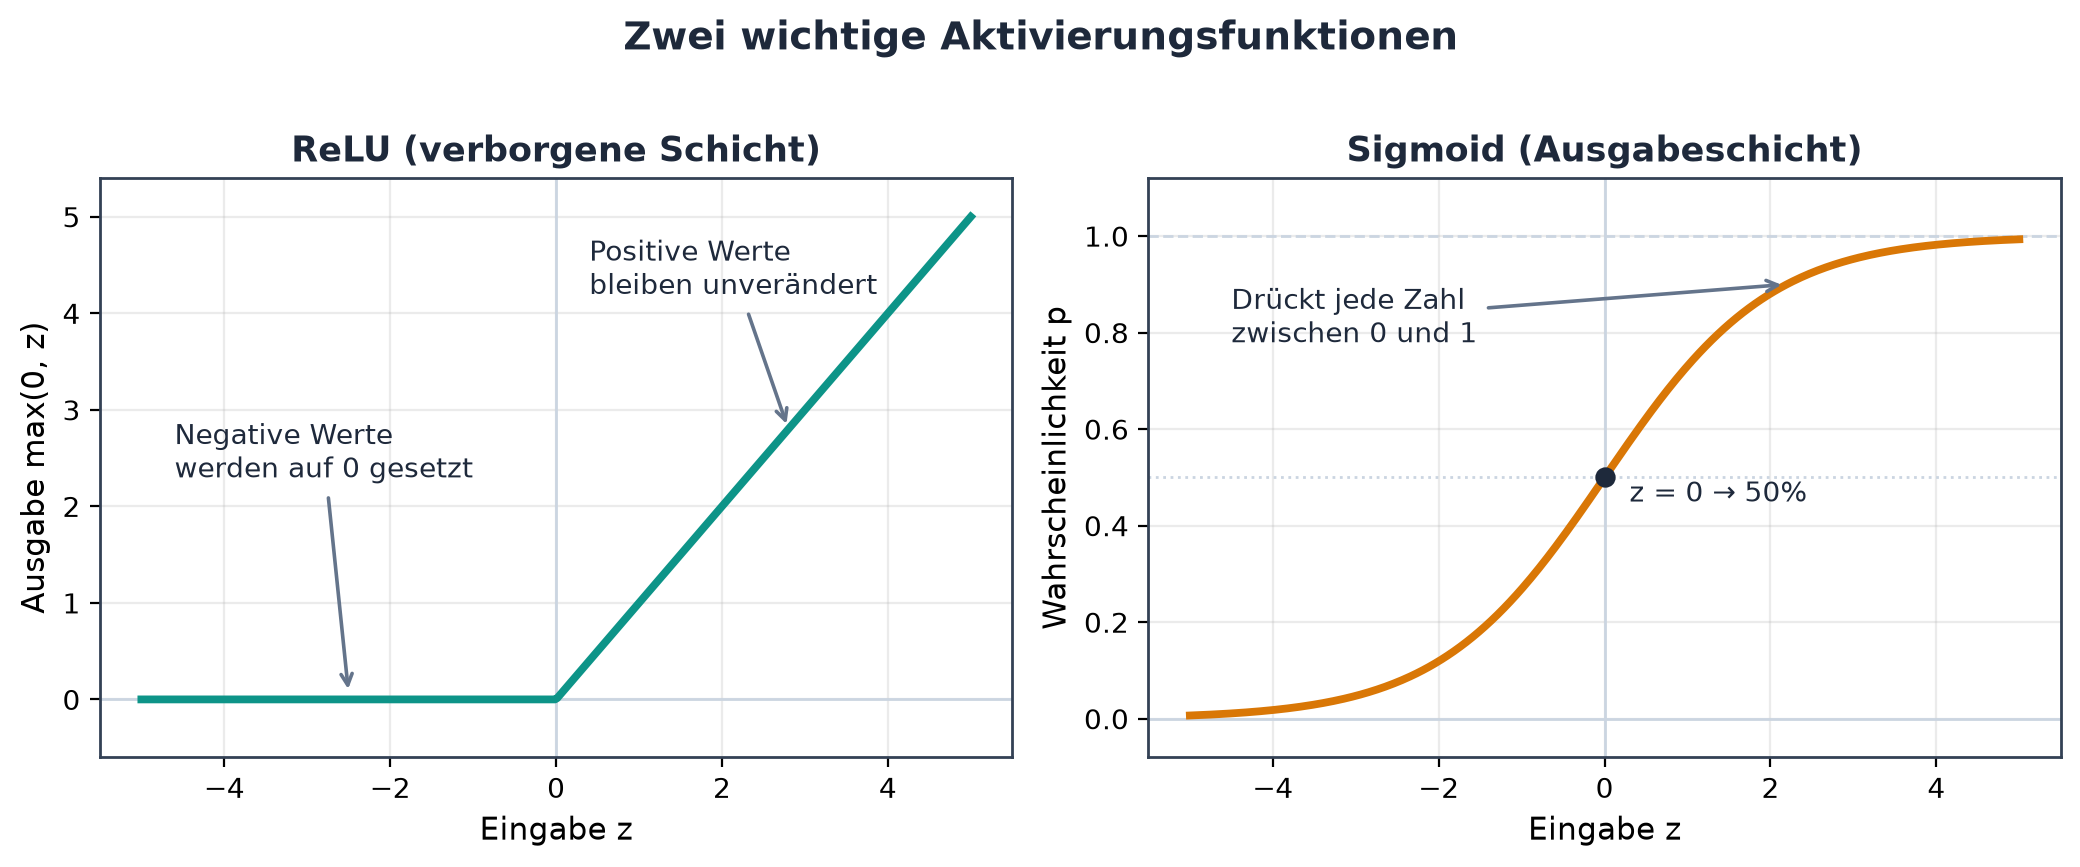

### 4.2 Ein Neuron selbst bauen (`class Neuron`)

Damit das Training später nicht wie eine schwarze Box wirkt, bauen wir zuerst
ein einzelnes Neuron als kleine Klasse mit nur 14 Zeilen.

Ein Objekt der Klasse `Neuron` speichert seine eigenen Gewichte `self.w` und
seinen Bias `self.b`. Es kann zwei Dinge:
- `vorhersage(x)`: berechnet `z = np.sum(self.w * x) + self.b` und drückt `z` mit Sigmoid zwischen 0 und 1.
- `lernschritt(x, y, lernrate)`: vergleicht Vorhersage `p` mit der echten Antwort `y` (`fehler = p - y`) und korrigiert `self.w` und `self.b` ein kleines Stück in Richtung kleinerer Fehler.

### Aufgabe 4: `vorhersage` und `lernschritt` vervollständigen

Ergänzt die vier fehlenden Zeilen in der Klasse `Neuron`.

In [14]:
class Neuron:
    """Ein einzelnes künstliches Neuron mit eigenen Gewichten und Bias."""

    def __init__(self, n_eingaben):
        self.w = np.array([0.4, -0.3, 0.2, 0.1, 0.5])[:n_eingaben]
        self.b = 0.0

    def vorhersage(self, x):
        z = np.sum(self.w * x) + self.b
        return 1 / (1 + np.exp(-z))

    def lernschritt(self, x, y, lernrate=0.3):
        p = self.vorhersage(x)
        fehler = p - y
        self.w = self.w - lernrate * fehler * x
        self.b = self.b - lernrate * fehler

Jetzt schauen wir unserem Neuron beim Lernen zu. Wir geben ihm ein echtes
aktives Trainingsmolekül (`y = 1`) und lassen es fünfmal `lernschritt()`
ausführen. Die Verlustfunktion (binäre Kreuzentropie) zeigt, wie falsch die
Vorhersage noch liegt.

In [15]:
# Ein echtes aktives Molekül aus den Trainingsdaten wählen
idx = np.where(y_train == 1)[0][0]
x_bsp = X_train_skaliert[idx]
y_bsp = y_train[idx]

neuron = Neuron(n_eingaben=5)

print(f"Echte Klasse dieses Moleküls: y = {int(y_bsp)}\n")
for schritt in range(6):
    p = neuron.vorhersage(x_bsp)
    kosten = -(y_bsp * np.log(p) + (1 - y_bsp) * np.log(1 - p))
    print(f"Schritt {schritt}: Vorhersage = {p:>5.1%} aktiv  |  Verlust = {kosten:.3f}")
    neuron.lernschritt(x_bsp, y_bsp, lernrate=0.3)

Echte Klasse dieses Moleküls: y = 1

Schritt 0: Vorhersage = 40.2% aktiv  |  Verlust = 0.912
Schritt 1: Vorhersage = 52.6% aktiv  |  Verlust = 0.642
Schritt 2: Vorhersage = 62.3% aktiv  |  Verlust = 0.473
Schritt 3: Vorhersage = 69.4% aktiv  |  Verlust = 0.365
Schritt 4: Vorhersage = 74.6% aktiv  |  Verlust = 0.293
Schritt 5: Vorhersage = 78.4% aktiv  |  Verlust = 0.243


Nach fünf Schritten steigt die Vorhersage für dieses Molekül deutlich an und
der Verlust fällt. Genau dieses schrittweise Bergabgehen heisst
**Gradientenabstieg**.

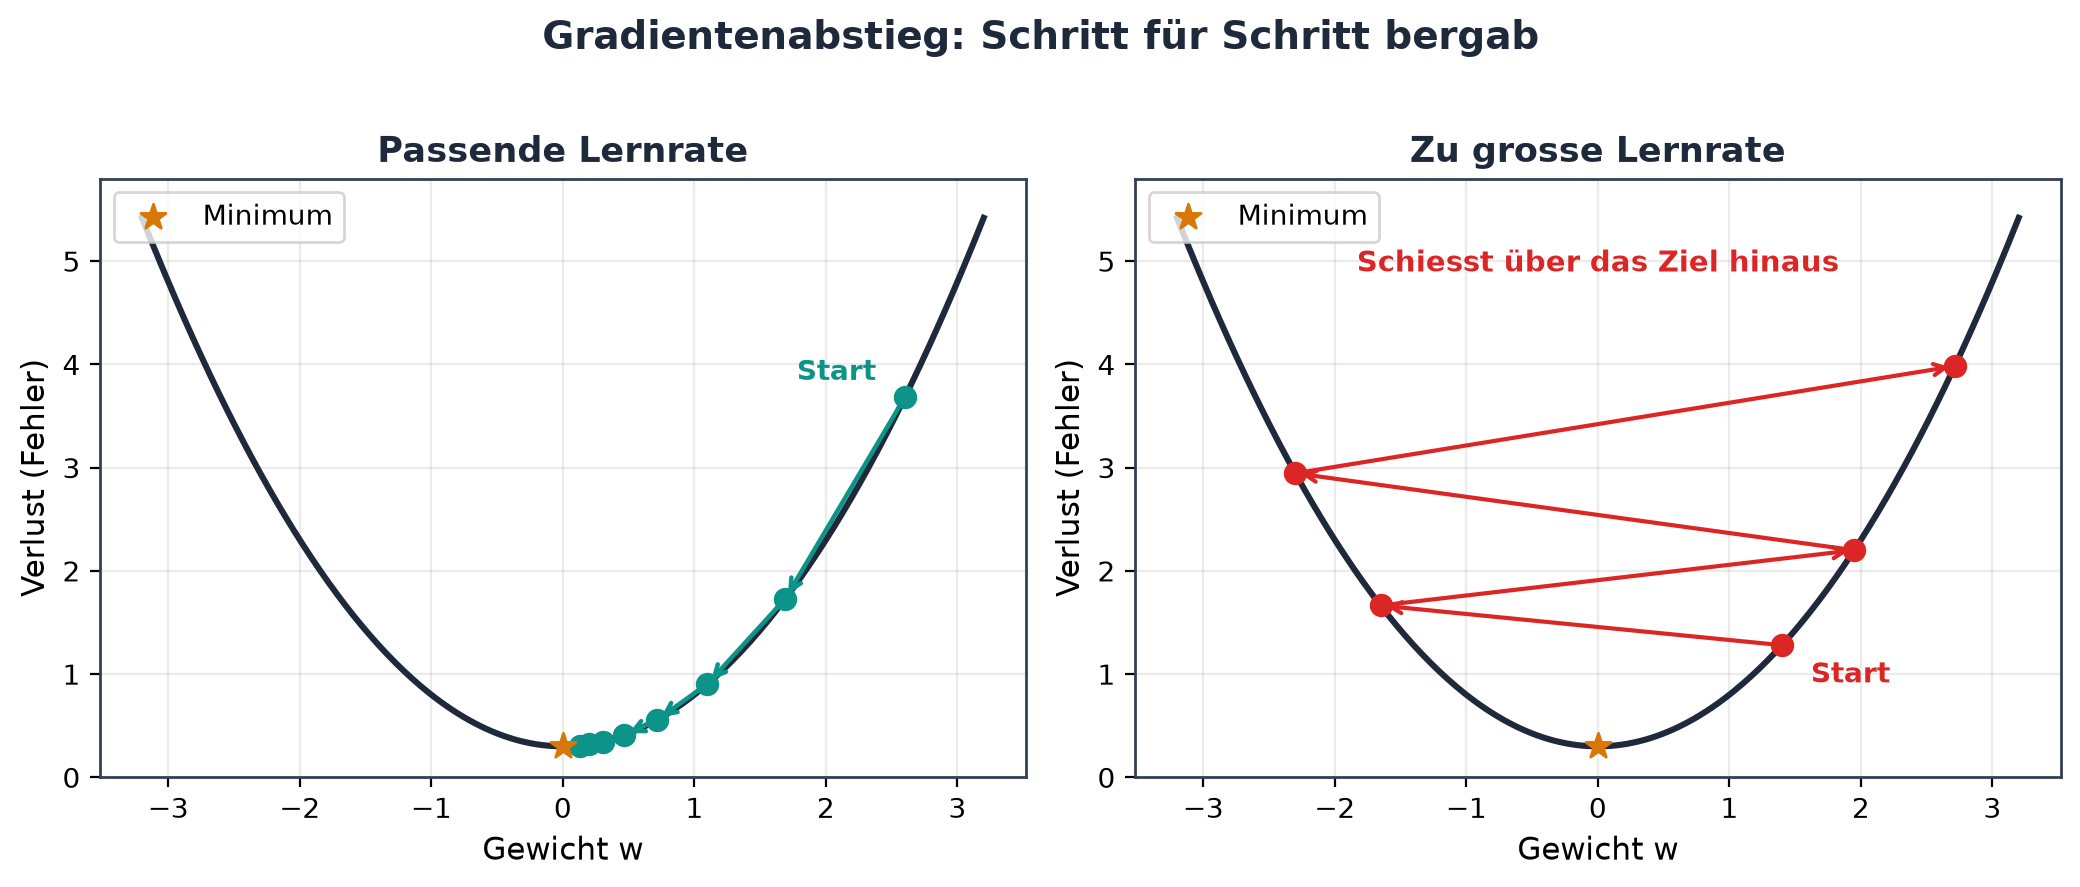

### 4.3 Vom einzelnen Neuron zum neuronalen Netz

Ein einzelnes Neuron hat nur 5 Gewichte und 1 Bias. Für kompliziertere Muster
schalten wir mehrere Neuronen zu **Schichten** zusammen. Unser Netz aus
`scikit-learn` (`MLPClassifier(hidden_layer_sizes=(8,))`) macht im Kern genau
denselben Lernschritt wie unsere Klasse `Neuron`, nur mit 8 Neuronen in einer
verborgenen Schicht und automatisch über alle 907 Trainingsmoleküle.

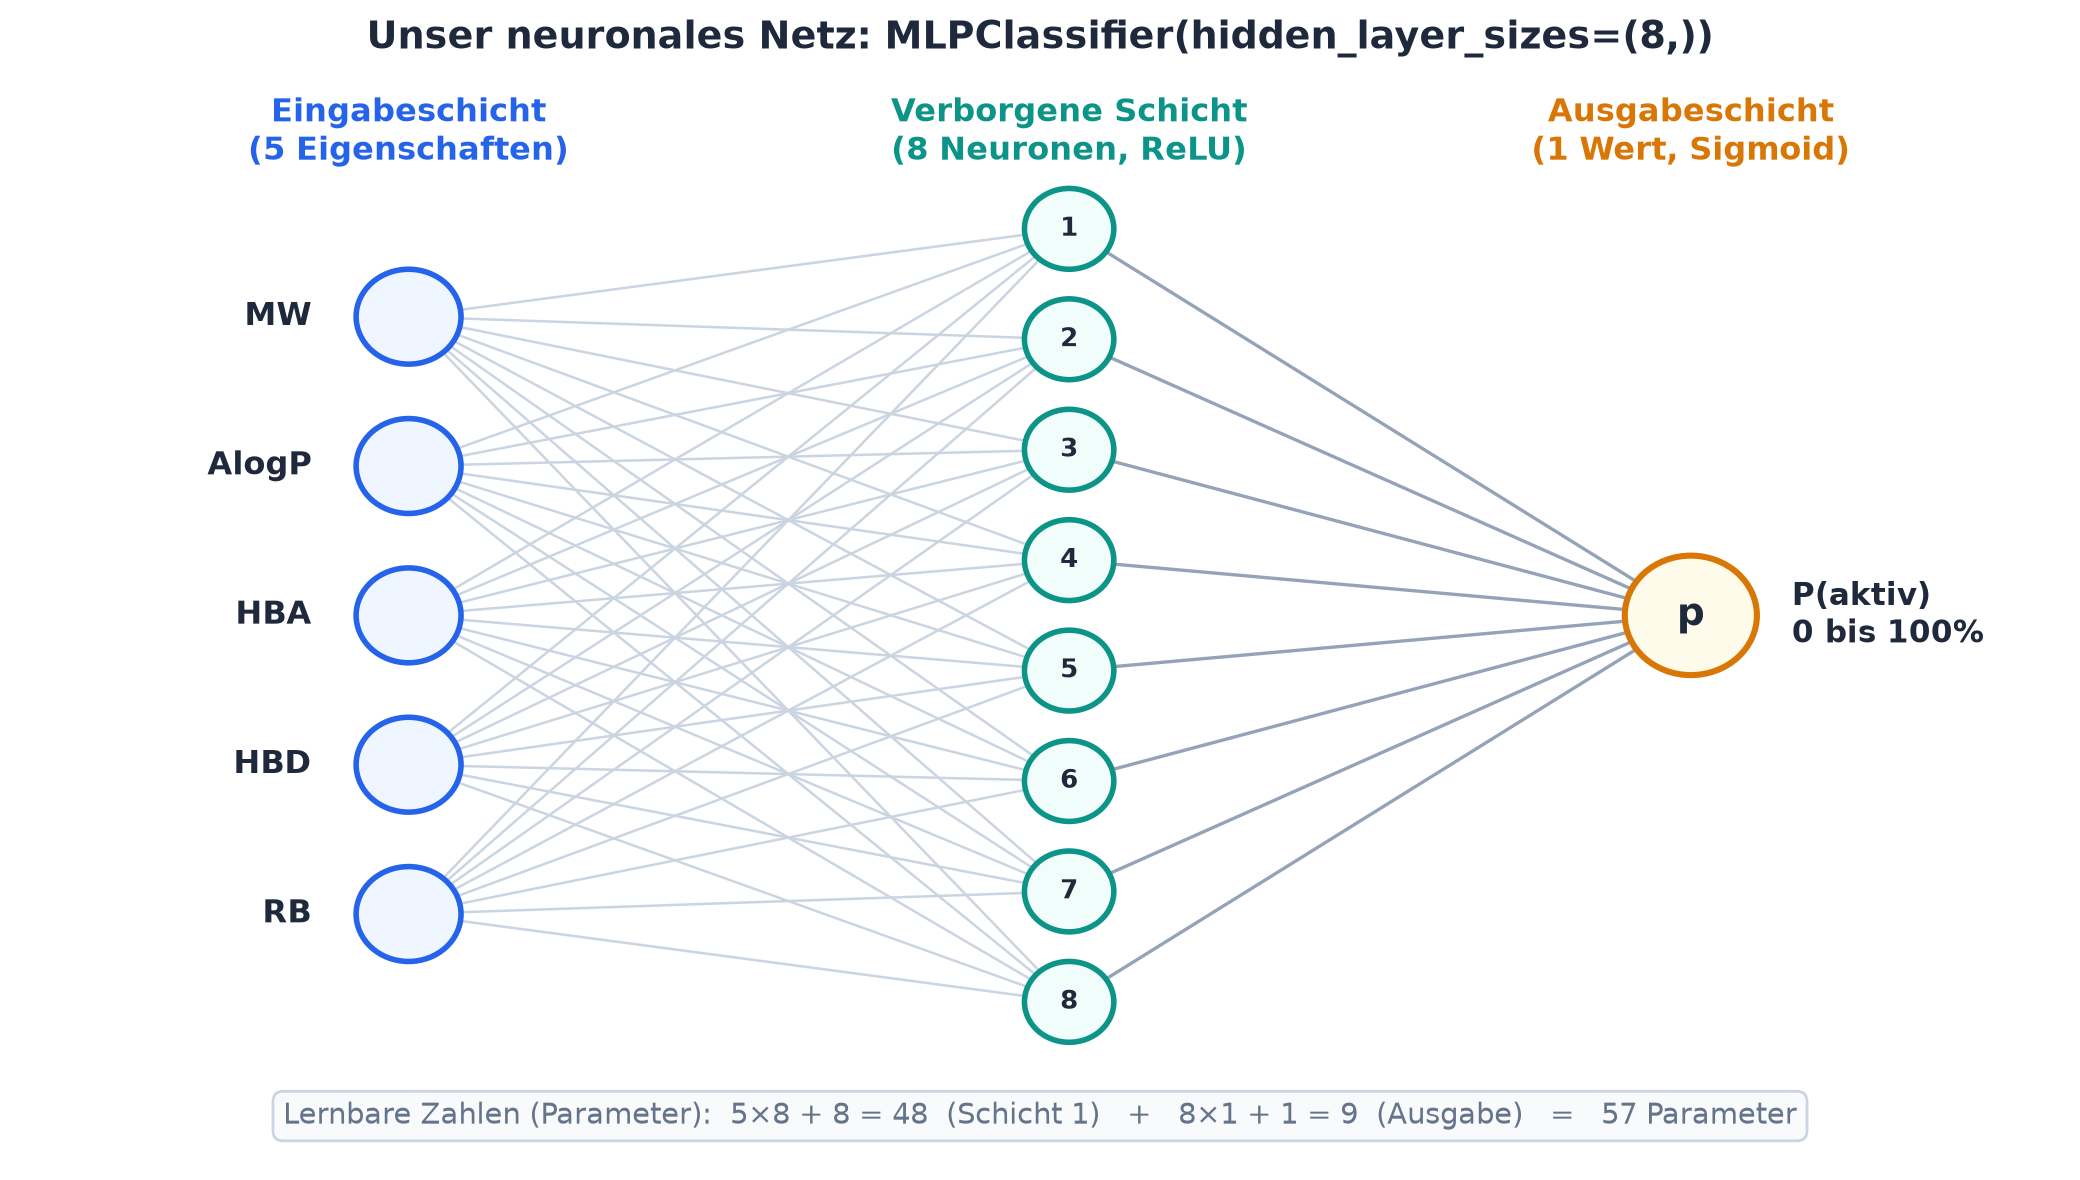

---

## Teil 5: Das ganze Netz mit `MLPClassifier` trainieren

Die wichtigsten Einstellungen von `MLPClassifier`:

| Einstellung | Bedeutung | Beispiele |
|---|---|---|
| `hidden_layer_sizes` | Schichten und Neuronen | `(8,)`, `(16, 8)`, `(64, 64, 32)` |
| `activation` | Aktivierungsfunktion in den verborgenen Schichten | `"relu"`, `"tanh"` |
| `learning_rate_init` | Schrittweite beim Lernen | `0.001` bis `0.1` |
| `alpha` | Strafe für zu grosse Gewichte (Regularisierung) | `0.0001` bis `0.5` |
| `max_iter` | maximale Anzahl Epochen | `1000` |

### Aufgabe 5: Modell erstellen und trainieren

Erstellt einen `MLPClassifier` mit `hidden_layer_sizes=(8,)`, `activation="relu"`,
`solver="adam"`, `learning_rate_init=0.01`, `max_iter=1000` und `random_state=42`.
Trainiert ihn mit `.fit(X_train_skaliert, y_train)`.

In [16]:
modell = MLPClassifier(
    hidden_layer_sizes=(8,),
    activation="relu",
    solver="adam",
    learning_rate_init=0.01,
    max_iter=1000,
    random_state=42,
)
modell.fit(X_train_skaliert, y_train)

print(f"Fertig nach {modell.n_iter_} Epochen")
print(f"Verlust am Anfang: {modell.loss_curve_[0]:.3f}")
print(f"Verlust am Ende:   {modell.loss_curve_[-1]:.3f}")
print("Form der gelernten Gewichte (Schicht 1):", modell.coefs_[0].shape)

Fertig nach 158 Epochen
Verlust am Anfang: 0.859
Verlust am Ende:   0.570
Form der gelernten Gewichte (Schicht 1): (5, 8)


### Verlustkurve und Kreuzentropie

`modell.loss_curve_` speichert den Fehler nach jeder Epoche. Das Netz hört vor
den 1000 Epochen auf, sobald sich der Verlust kaum noch verbessert.

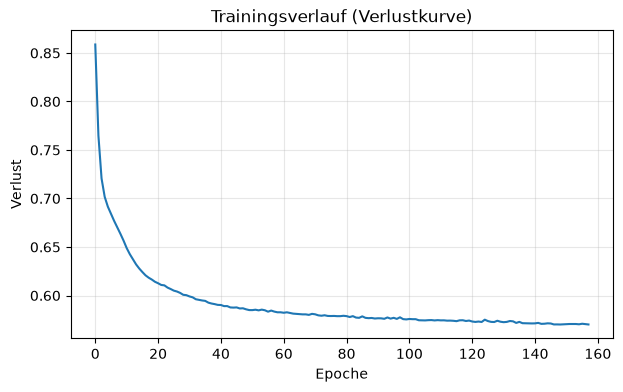

In [17]:
plt.figure(figsize=(7, 4))
plt.plot(modell.loss_curve_)
plt.xlabel("Epoche")
plt.ylabel("Verlust")
plt.title("Trainingsverlauf (Verlustkurve)")
plt.grid(alpha=0.3)
plt.show()

Die binäre Kreuzentropie bestraft falsche Vorhersagen umso stärker, je sicherer
sich das Modell war:

In [18]:
def verlust(modell, X, y):
    p = modell.predict_proba(X)[:, 1]
    p = np.clip(p, 1e-7, 1 - 1e-7)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))


for p in [0.99, 0.9, 0.6, 0.5, 0.4, 0.1, 0.01]:
    print(f"Modell sagt {p:>5.0%} aktiv, Molekül ist aktiv  -> Kosten {-np.log(p):.2f}")

Modell sagt   99% aktiv, Molekül ist aktiv  -> Kosten 0.01
Modell sagt   90% aktiv, Molekül ist aktiv  -> Kosten 0.11
Modell sagt   60% aktiv, Molekül ist aktiv  -> Kosten 0.51
Modell sagt   50% aktiv, Molekül ist aktiv  -> Kosten 0.69
Modell sagt   40% aktiv, Molekül ist aktiv  -> Kosten 0.92
Modell sagt   10% aktiv, Molekül ist aktiv  -> Kosten 2.30
Modell sagt    1% aktiv, Molekül ist aktiv  -> Kosten 4.61


### Genauigkeit, Basislinie und Konfusionsmatrix

Eine Genauigkeit allein sagt wenig aus. Wenn wir immer die häufigere Klasse
(`inaktiv`) raten, erreichen wir schon `54.5%`.

In [19]:
def genauigkeit(modell, X, y):
    return (modell.predict(X) == y).mean()


print("                  Training   Validierung")
print(f"Genauigkeit:         {genauigkeit(modell, X_train_skaliert, y_train):.3f}      "
      f"{genauigkeit(modell, X_val_skaliert, y_val):.3f}")
print(f"Verlust:             {verlust(modell, X_train_skaliert, y_train):.3f}      "
      f"{verlust(modell, X_val_skaliert, y_val):.3f}")

raten = max(y_val.mean(), 1 - y_val.mean())
print(f"\nImmer die häufigere Klasse raten: {raten:.3f}")

                  Training   Validierung
Genauigkeit:         0.714      0.693
Verlust:             0.569      0.576

Immer die häufigere Klasse raten: 0.545


Die Konfusionsmatrix zeigt auf den Validierungsdaten die vier Fälle. Ein
**Falsch-Positiv** kostet teure Laborzeit für ein unwirksames Molekül, ein
**Falsch-Negativ** übersieht einen möglichen Wirkstoff.

In [20]:
vorhersage = modell.predict(X_val_skaliert)

print("                   vorhergesagt")
print("                 inaktiv   aktiv")
for echt, bezeichnung in [(0, "echt inaktiv"), (1, "echt aktiv  ")]:
    zeile = [np.sum((y_val == echt) & (vorhersage == p)) for p in (0, 1)]
    print(f"{bezeichnung}  {zeile[0]:>7}{zeile[1]:>8}")

                   vorhergesagt
                 inaktiv   aktiv
echt inaktiv      129      36
echt aktiv         57      81


---

## Teil 6: Überanpassung und Grenzen des Modells

### 6.1 Mehr Neuronen sind nicht automatisch besser

Wir vergleichen verschiedene Netzgrössen auf **Training** und **Validierung**.
Die Testdaten bleiben dabei weiterhin unberührt.

In [21]:
def vergleiche(varianten):
    print(f"{'Neuronen':<14}{'Aktiv.':<8}{'alpha':<8}{'Epochen':>8}{'Training':>10}{'Valid.':>8}")
    print("-" * 56)

    for v in varianten:
        m = MLPClassifier(
            hidden_layer_sizes=v.get("neuronen", (8,)),
            activation=v.get("aktivierung", "relu"),
            solver="adam",
            learning_rate_init=v.get("lernrate", 0.01),
            alpha=v.get("alpha", 0.0001),
            max_iter=1500,
            random_state=42,
        )
        m.fit(X_train_skaliert, y_train)

        print(f"{str(v.get('neuronen', (8,))):<14}"
              f"{v.get('aktivierung', 'relu'):<8}"
              f"{v.get('alpha', 0.0001):<8.4f}"
              f"{m.n_iter_:>8}"
              f"{genauigkeit(m, X_train_skaliert, y_train):>10.3f}"
              f"{genauigkeit(m, X_val_skaliert, y_val):>8.3f}")


vergleiche([
    {"neuronen": (2,)},
    {"neuronen": (8,)},
    {"neuronen": (16, 8)},
    {"neuronen": (32, 16)},
    {"neuronen": (64, 64, 32), "aktivierung": "tanh"},
    {"neuronen": (64, 64, 32), "alpha": 0.5},
])

Neuronen      Aktiv.  alpha    Epochen  Training  Valid.
--------------------------------------------------------
(2,)          relu    0.0001       234     0.678   0.690


(8,)          relu    0.0001       158     0.714   0.693


(16, 8)       relu    0.0001       156     0.791   0.749
(32, 16)      relu    0.0001       139     0.851   0.719


(64, 64, 32)  tanh    0.0001       195     0.969   0.706
(64, 64, 32)  relu    0.5000        76     0.795   0.739


Schaut euch die vorletzte Zeile (`(64, 64, 32)` mit `tanh`) an: `96.9%` auf den
Trainingsdaten, aber nur `70.6%` auf den Validierungsdaten. Das Netz hat die
Trainingsbeispiele auswendig gelernt, statt allgemeine Muster zu finden. Das
heisst **Überanpassung (Overfitting)**.

Die letzte Zeile zeigt ein Gegenmittel: Mit grösserem `alpha=0.5` bestraft das
Netz zu grosse Gewichte. Die Trainingsgenauigkeit sinkt, aber die
Validierungsgenauigkeit steigt wieder auf `73.9%`.

### 6.2 Ehrliche Endprüfung auf den Testdaten

Auf den Validierungsdaten hat `(16, 8)` mit `relu` am besten abgeschnitten
(`74.9%`). Jetzt prüfen wir dieses gewählte Modell genau einmal auf dem bisher
unberührten **Testdatensatz**:

In [22]:
bestes_modell = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    activation="relu",
    solver="adam",
    learning_rate_init=0.01,
    max_iter=1500,
    random_state=42,
)
bestes_modell.fit(X_train_skaliert, y_train)

test_genauigkeit = genauigkeit(bestes_modell, X_test_skaliert, y_test)
test_raten = max(y_test.mean(), 1 - y_test.mean())

print(f"Test-Genauigkeit: {test_genauigkeit:.1%}  (Basislinie Raten: {test_raten:.1%})")

Test-Genauigkeit: 69.0%  (Basislinie Raten: 54.5%)


### 6.3 Eigene Moleküle testen und Grenzen erkennen

Jetzt füttern wir bekannte Alltagsmoleküle und einen echten BACE-Inhibitor aus
dem Datensatz in unser Modell. Jedes neue Molekül muss mit demselben `skalierer`
umgerechnet werden wie die Trainingsdaten.

In [23]:
def teste_molekuel(mw, alogp, hba, hbd, rb, name="Neues Molekül"):
    roh = np.array([[mw, alogp, hba, hbd, rb]])
    neu = skalierer.transform(roh)

    sicherheit = modell.predict_proba(neu)[0][1]
    antwort = "wirkt vermutlich" if sicherheit > 0.5 else "wirkt vermutlich nicht"

    unter = roh[0] < X_train.min(axis=0)
    ueber = roh[0] > X_train.max(axis=0)
    ausserhalb = [namen[i] for i in range(len(namen)) if unter[i] or ueber[i]]
    hinweis = f"  [ausserhalb Trainingsbereich: {', '.join(ausserhalb)}]" if ausserhalb else ""

    print(f"{name:<18} {antwort:<24} ({sicherheit:>3.0%}){hinweis}")


#               MW     AlogP  HBA HBD RB
teste_molekuel(180.2,   1.31,  3,  1,  2, name="Aspirin")
teste_molekuel(206.3,   3.07,  1,  1,  4, name="Ibuprofen")
teste_molekuel(657.8,   2.64,  5,  4, 16, name="BACE-Inhibitor")
teste_molekuel(194.2,  -1.03,  3,  0,  0, name="Koffein")

Aspirin            wirkt vermutlich nicht   ( 4%)
Ibuprofen          wirkt vermutlich nicht   ( 1%)
BACE-Inhibitor     wirkt vermutlich         (86%)
Koffein            wirkt vermutlich         (82%)  [ausserhalb Trainingsbereich: HBD]


**Schaut euch das Ergebnis kritisch an.** Warum bekommt **Koffein** eine hohe
Wahrscheinlichkeit (`82%`), obwohl es kein Wirkstoff gegen Alzheimer ist?

1. **Ausserhalb des Trainingsbereichs (Extrapolation):** Kein einziges Molekül
   in den Trainingsdaten hat `HBD = 0`, und auch `AlogP = -1.03` sowie
   `MW = 194.2` liegen ganz am unteren Rand. In Bereichen, die das Netz nie
   gesehen hat, rät es im Grunde.
2. **Zu grobe Merkmale:** Das Modell kennt von jedem Molekül nur fünf
   Summenzahlen (Lipinski-Eigenschaften), nicht seine dreidimensionale Struktur.
   Echte Modelle in der Wirkstoffforschung nutzen strukturelle Fingerabdrücke
   oder Molekülgraphen.

---

## Teil 7 (Optional): Top-10-Kandidaten fürs Labor

In der Praxis testet man im Labor nicht alle Moleküle, sondern nur die
vielversprechendsten Kandidaten. Statt nur bei `50%` zu schneiden, sortieren
wir die Testmoleküle nach ihrer vorhergesagten Wahrscheinlichkeit.

### Aufgabe 6 (Optional): Die 10 besten Kandidaten auswählen

1. Berechnet `wahrscheinlichkeiten = bestes_modell.predict_proba(X_test_skaliert)[:, 1]`.
2. Findet mit `np.argsort(wahrscheinlichkeiten)[-10:][::-1]` die Indizes der 10
   höchsten Werte.
3. Zählt, wie viele dieser 10 Moleküle in `y_test` tatsächlich aktiv (`1`) sind.

In [24]:
wahrscheinlichkeiten = bestes_modell.predict_proba(X_test_skaliert)[:, 1]
top10_idx = np.argsort(wahrscheinlichkeiten)[-10:][::-1]

treffer = int(y_test[top10_idx].sum())
print(f"Unter den Top-10-Kandidaten sind {treffer} von 10 wirklich aktiv ({treffer * 10}%).")
print()
for rang, idx in enumerate(top10_idx, start=1):
    status = "aktiv" if y_test[idx] == 1 else "inaktiv"
    print(f"Rang {rang:>2}: vorhergesagt {wahrscheinlichkeiten[idx]:>5.1%}  |  echt: {status}")

Unter den Top-10-Kandidaten sind 7 von 10 wirklich aktiv (70%).

Rang  1: vorhergesagt 99.9%  |  echt: inaktiv
Rang  2: vorhergesagt 98.1%  |  echt: aktiv
Rang  3: vorhergesagt 98.0%  |  echt: aktiv
Rang  4: vorhergesagt 97.7%  |  echt: inaktiv
Rang  5: vorhergesagt 97.7%  |  echt: aktiv
Rang  6: vorhergesagt 97.4%  |  echt: aktiv
Rang  7: vorhergesagt 97.4%  |  echt: aktiv
Rang  8: vorhergesagt 97.3%  |  echt: inaktiv
Rang  9: vorhergesagt 97.1%  |  echt: aktiv
Rang 10: vorhergesagt 96.8%  |  echt: aktiv


### Weitere Ideen zum Ausprobieren

- Ergänzt die Klasse `Datensatz` um eine Methode `groesstes_molekuel()`, die die höchste Molekülmasse (`MW`) zurückgibt.
- Setzt `learning_rate_init` auf `0.5` und schaut euch die neue Verlustkurve an.
- Ergänzt in `vergleiche` eine Spalte für die Lernrate und testet `0.001`, `0.01` und `0.1`.
- Sucht auf Wikipedia ein eigenes Medikament heraus und lasst es von `teste_molekuel` bewerten.